### Data Understanding

#### 1. Project Overview

This project focuses on developing an end-to-end credit card fraud detection system using machine learning.

The initial implementation is based on the Kaggle Playground Series Season 6, Episode 11 competition.

The project will progressively explore statistical analysis, exploratory data analysis, feature engineering, machine learning, model evaluation, and production-oriented deployment.

#### 2. Business Problem

Credit card fraud presents a significant challenge to financial institutions because fraudulent transactions can result in financial losses, operational costs, and reduced customer trust.

The objective is to develop a machine learning model capable of identifying potentially fraudulent transactions based on transaction-related features.

The model should distinguish between legitimate and fraudulent transactions while considering the different costs associated with false positives and false negatives.

#### 3. Project Objectives

- Understand the dataset and its underlying structure.
- Investigate transaction characteristics and fraud patterns.
- Apply statistical techniques to understand the data.
- Develop and evaluate classification models.
- Explore approaches for handling class imbalance.
- Build a reproducible and deployable fraud detection system.

#### 4. Initial Scope

This notebook focuses on understanding the available datasets, identifying their structures, assessing basic data quality, and documenting initial observations.


#### STEP 1: Import Dependencies

In [1]:
# Standard library
from pathlib import Path

# Third-party libraries
import pandas as pd
import matplotlib.pyplot as plt

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)

# Reproducibility
RANDOM_STATE = 42

In [2]:
# Project configuration
# Project root
PROJECT_ROOT = Path.cwd().parent

# Data directory
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Raw dataset paths
TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

# Verify files exist
for file_path in [
    TRAIN_PATH,
    TEST_PATH
]:
    print(f"{file_path.name}: {file_path.exists()}")

train.csv: True
test.csv: True


In [3]:
# Load datasets
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

#### STEP 2: Data Inspection

In [4]:
def check_df(df):
    # Check summary of df

    print(f"Shape: {df.shape}")

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\nFirst 5 Rows:")
    display(df.head())

check_df(train_df)

Shape: (699960, 26)

Data Types:
id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_g

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.1600,9.7700,1,17.7800,48,56,1269.3500,0,5.5000,17,3,29.2000,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0000
1,1,24.8300,1.5400,3,13.0600,38,28,3233.0000,0,33.4000,23,5,29.9000,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0000
2,2,6.3600,1.2000,4,8.1700,50,55,1046.8800,0,35.8000,15,0,24.1000,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0000
3,3,37.4400,5.1300,4,8.6700,48,48,2217.6700,0,20.7000,7,3,41.9000,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0000
4,4,653.8500,0.8000,4,11.6900,37,52,3291.0600,0,34.8000,4,4,48.0000,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0000


In [5]:
# Compare dataset dimensions
print("Training:", train_df.shape)
print("Testing:", test_df.shape)


Training: (699960, 26)
Testing: (299984, 25)


#### 2.1 Target distribution

In [ ]:
train_df["is_fraud"].value_counts()

is_fraud
0.0000    688271
1.0000     11689
Name: count, dtype: int64

In [7]:
train_df["is_fraud"].value_counts(normalize=True) * 100

is_fraud
0.0000   98.3300
1.0000    1.6700
Name: proportion, dtype: float64

In [ ]:
# Identifier Inspection
# Inspect target values and identifier uniqueness
print("Target unique values:", train_df["is_fraud"].unique())
print("ID unique:", train_df["id"].is_unique)
print("Test ID unique:", test_df["id"].is_unique)

Target unique values: [0. 1.]
ID unique: True
Test ID unique: True


#### STEP 3: Univariate Analysis

#### 3.1 : Feature Classification

In [ ]:
# Features (categorical & numerical)

features = train_df.drop(columns=["id", "is_fraud"])

features.dtypes

amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool
dtype: object

#### 3.2 : Categorical Cardinality

In [13]:
# Categorical features

categorical_cols = features.select_dtypes(include=["str"]).columns

for col in categorical_cols:
    print(f"\n{col}")
    print(f"Unique values: {features[col].nunique()}")
    print(features[col].value_counts())


merchant_category
Unique values: 12
merchant_category
Online Retail      155097
Groceries          142578
Restaurants        101360
Fuel                59880
Electronics         48693
Streaming           47196
Utilities           42027
Healthcare          35889
Travel              28715
Gaming              23784
Gift Cards           9456
Crypto Exchange      5285
Name: count, dtype: int64

card_type
Unique values: 5
card_type
Visa          345001
Mastercard    254857
Amex           45797
RuPay          37070
Discover       17235
Name: count, dtype: int64

auth_method
Unique values: 5
auth_method
3D Secure            210036
OTP                  175178
PIN                  154020
Biometric             93666
No Authentication     67060
Name: count, dtype: int64

channel
Unique values: 5
channel
Online         273939
POS            206465
Contactless    105620
In-App          83716
ATM             30220
Name: count, dtype: int64

device_type
Unique values: 8
device_type
Android Phone    2

#### 3.3 Missing values in features


In [ ]:
# Training data
train_missing = train_df.isna().sum()

print("Training missing values:")
print(train_missing[train_missing > 0])

# Testing data
test_missing = test_df.isna().sum()

print("\nTesting missing values:")
print(test_missing[test_missing > 0])

Training missing values:
Series([], dtype: int64)

Testing missing values:
Series([], dtype: int64)


#### 4.4 Duplicate Inspection

In [16]:
# Check duplicate rows
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


In [17]:
print("Training duplicate IDs:", train_df["id"].duplicated().sum())
print("Testing duplicate IDs:", test_df["id"].duplicated().sum())

Training duplicate IDs: 0
Testing duplicate IDs: 0


#### 3.5 : Descriptive Statistics

In [18]:
features.describe().T

,count,mean,std,min,25%,50%,75%,max
amount_usd,699960.0000,79.8931,205.1735,1.0000,15.8100,27.2500,43.1100,6872.6900
hours_since_last_txn,699960.0000,6.6337,6.2901,0.0100,2.1100,4.7300,9.1900,51.9800
txn_count_last_24h,699960.0000,2.9841,1.4990,0.0000,2.0000,3.0000,4.0000,11.0000
distance_from_home_km,699960.0000,13.5876,11.6173,0.0000,4.4300,10.2200,19.7500,57.9300
card_age_months,699960.0000,46.8630,5.5792,25.0000,43.0000,47.0000,51.0000,73.0000
customer_age,699960.0000,51.4303,17.8991,18.0000,38.0000,52.0000,66.0000,81.0000
account_balance_usd,699960.0000,2064.9981,3400.1329,58.2500,834.1200,1382.7400,2517.0200,99701.3900
cvv_retry_count,699960.0000,0.0855,0.2895,0.0000,0.0000,0.0000,0.0000,3.0000
velocity_score,699960.0000,18.9294,10.8644,0.0000,11.4000,18.6000,26.0000,72.9000
time_of_day_hour,699960.0000,11.7619,6.8692,0.0000,6.0000,12.0000,18.0000,23.0000


#### 3.6 : Feature Distributions

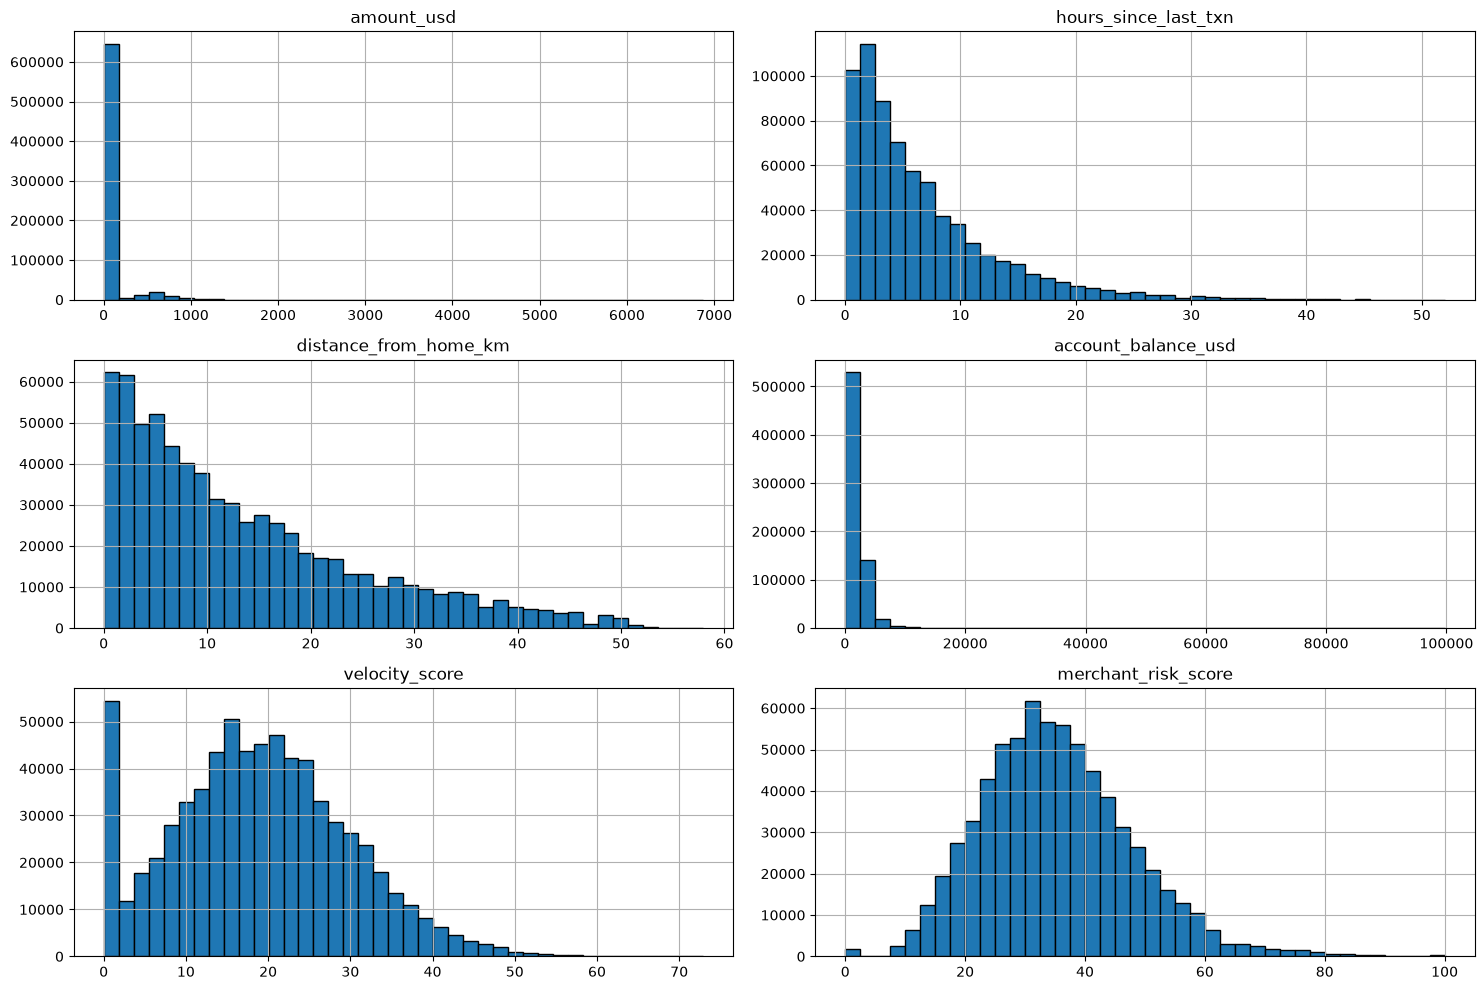

In [ ]:
# Continous col features
continuous_cols = [
    "amount_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "account_balance_usd",
    "velocity_score",
    "merchant_risk_score"
]

features[continuous_cols].hist(
    bins=40,
    figsize=(15, 10),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

#### 3.8 : Outlier Investigation

In [21]:
outlier_summary = []

for col in continuous_cols:
    q1 = features[col].quantile(0.25)
    q3 = features[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (features[col] < lower_bound) |
        (features[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "feature": col,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": outliers,
        "outlier_percentage": (outliers / len(features)) * 100
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df.round(2)

,feature,lower_bound,upper_bound,outlier_count,outlier_percentage
0,amount_usd,-25.1400,84.0600,70741,10.1100
1,hours_since_last_txn,-8.5100,19.8100,32816,4.6900
2,distance_from_home_km,-18.5500,42.7300,16770,2.4000
3,account_balance_usd,-1690.2300,5041.3700,29068,4.1500
4,velocity_score,-10.5000,47.9000,4276,0.6100
5,merchant_risk_score,1.9500,67.1500,13028,1.8600


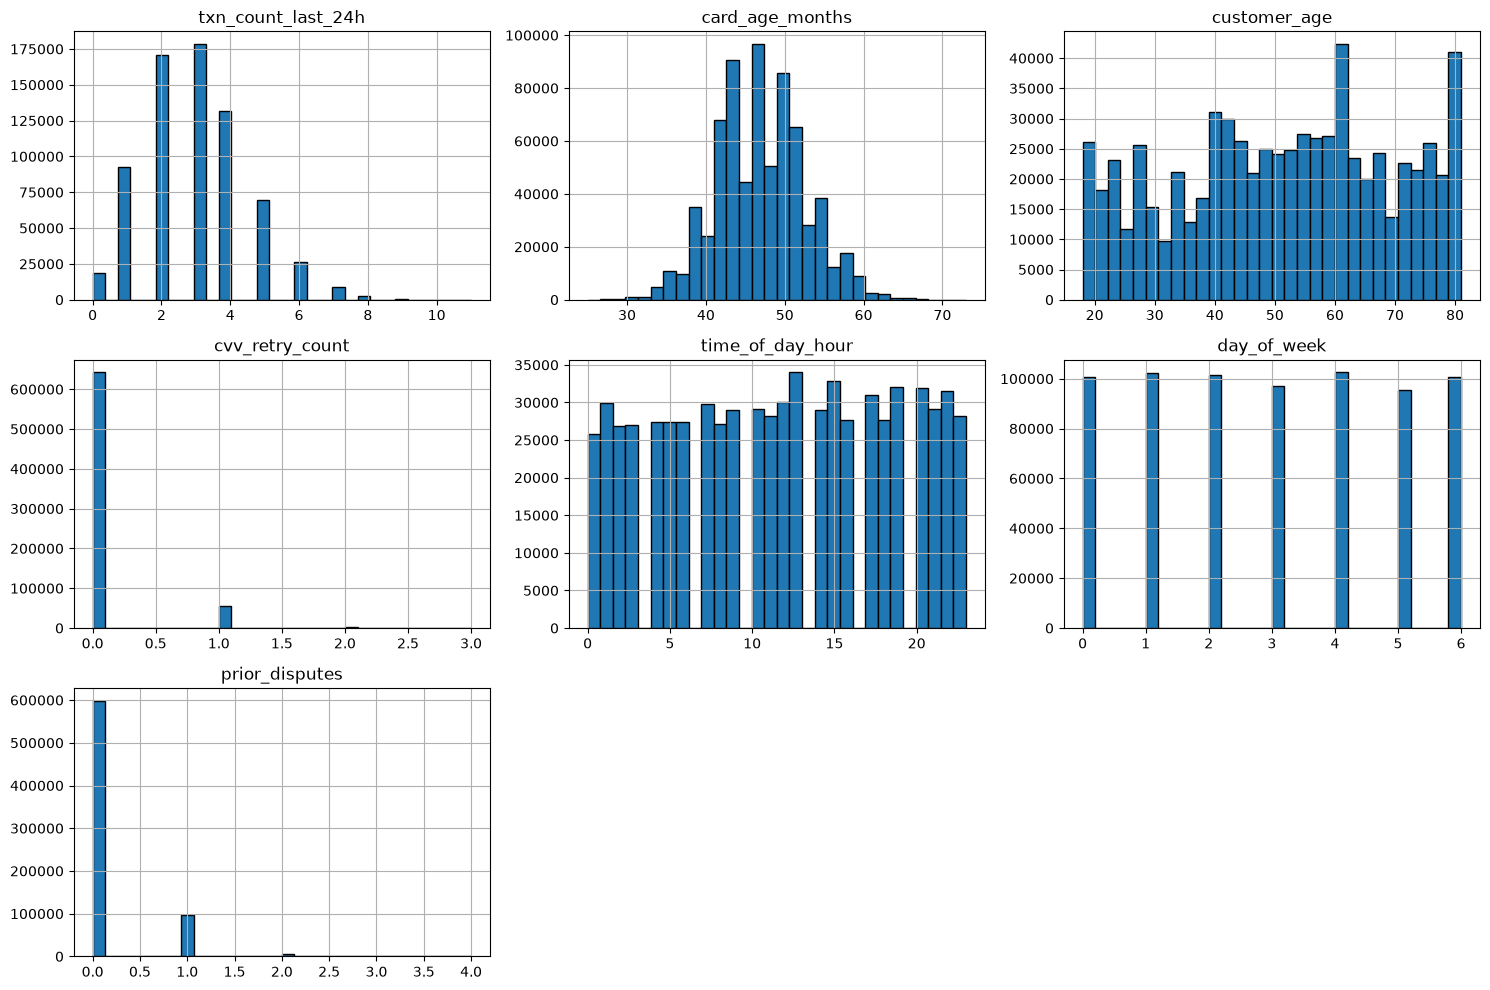

In [22]:
# Discrete col features

discrete_cols = [
    "txn_count_last_24h",
    "card_age_months",
    "customer_age",
    "cvv_retry_count",
    "time_of_day_hour",
    "day_of_week",
    "prior_disputes"
]

features[discrete_cols].hist(
    bins=30,
    figsize=(15, 10),
    edgecolor="black"
)

plt.tight_layout()
plt.show()


In [ ]:
# zero-heavy features 

count_cols = [
    "txn_count_last_24h",
    "cvv_retry_count",
    "prior_disputes"
]

for col in count_cols:
    print(f"\n{col}")
    print(features[col].value_counts(normalize=True).sort_index().mul(100).round(2))


txn_count_last_24h
txn_count_last_24h
0     2.6400
1    13.2400
2    24.4000
3    25.4800
4    18.8400
5     9.9600
6     3.7800
7     1.2700
8     0.3200
9     0.0500
10    0.0100
11    0.0000
Name: proportion, dtype: float64

cvv_retry_count
cvv_retry_count
0   91.7300
1    7.9900
2    0.2700
3    0.0000
Name: proportion, dtype: float64

prior_disputes
prior_disputes
0   85.4900
1   13.7700
2    0.7200
3    0.0200
4    0.0000
Name: proportion, dtype: float64


#### STEP 4: Bivariate Analysis
#### 4.1 : Numerical Features vs Target